# 04 · Structured worlds: a corridor and a closed loop

The random world places a few landmarks anywhere, and a 50-unit sensing window sees most of them from most places. These two worlds are closer to how a mobile robot actually sees a building. Landmarks line a path, the sensor only reaches nearby ones, and the robot follows a route.

Both use `world.simulate_waypoints`. The robot follows the waypoints with a simple path follower: each step it commands a move of 5 units toward the next waypoint, computed from its true position, like a robot tracking a line on the floor. The commanded move is reported as odometry, and the executed move adds noise. The robot therefore stays on the route, while anything that integrates odometry drifts away from it.

Both worlds use motion noise 3 and measurement noise 1. The odometry is the weak sensor here, so landmarks have to carry the estimate.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make project modules importable
ASSETS = Path.cwd().parent / "assets"

import matplotlib.pyplot as plt
import numpy as np

import metrics
import slam
import viz
import world

RUN = dict(step=5.0, motion_noise=3.0, measurement_noise=1.0)

## Corridor

The corridor has two rows of landmarks along its walls, 10 units apart, and the robot drives from one end to the other and back. With a sensing range of 8, the robot sees only the 2–4 landmarks next to it.

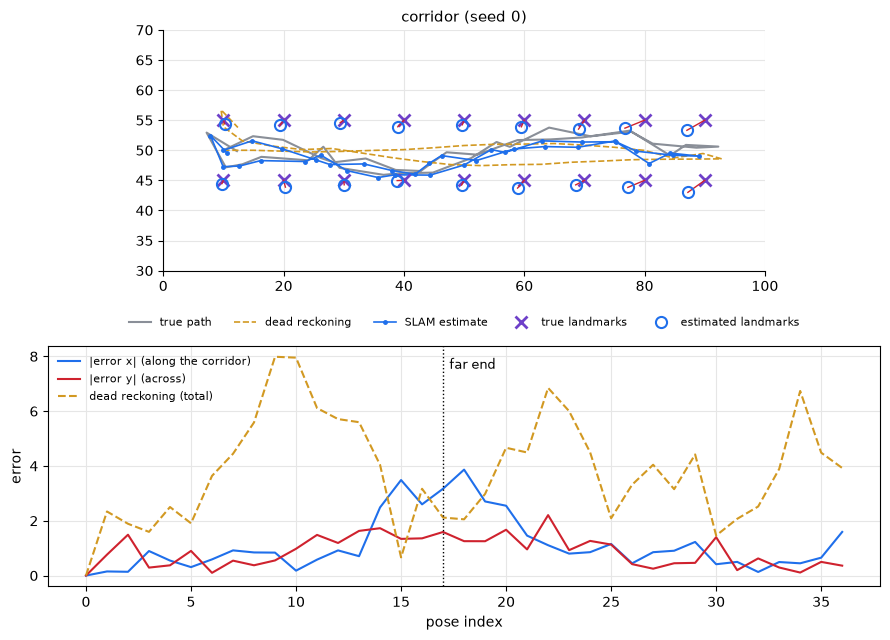

pose error: far end 3.55, final 1.63, max 4.06
mean |error x| 1.12, mean |error y| 0.88
{'final_pose_err': 1.6330714813892264, 'pose_rmse': 1.8200044728503684, 'landmark_rmse': 1.8885162691394606, 'dr_final_pose_err': 3.9258431253916664, 'dr_pose_rmse': 4.2665904579082214}


In [2]:
waypoints, landmarks = world.corridor_world()
cor = world.simulate_waypoints(waypoints, landmarks, measurement_range=8.0, seed=0, name="corridor", **RUN)
P, L = slam.slam_observed(cor.data, cor.num_landmarks, **cor.slam_args())
dr = metrics.dead_reckoning(cor.data, cor.start)
err = np.abs(P - cor.true_poses)
far = int(np.argmax(cor.true_poses[:, 0]))

fig, (a, b) = plt.subplots(2, 1, figsize=(9, 6.5), gridspec_kw=dict(height_ratios=[1, 1]))
viz.plot_world(a, cor.world_size, true_poses=cor.true_poses, est_poses=P, dr_poses=dr,
               true_landmarks=cor.landmarks, est_landmarks=L, legend=False, title="corridor (seed 0)")
a.set_ylim(30, 70)
a.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=5, fontsize=8, frameon=False)
t = np.arange(cor.N)
b.plot(t, err[:, 0], "-", color=viz.EST, label="|error x| (along the corridor)")
b.plot(t, err[:, 1], "-", color=viz.ERR, label="|error y| (across)")
b.plot(t, np.linalg.norm(dr - cor.true_poses, axis=1), "--", color=viz.DR, label="dead reckoning (total)")
b.axvline(far, color="k", ls=":", lw=1)
b.text(far + 0.3, b.get_ylim()[1] * 0.9, "far end", fontsize=9)
b.set_xlabel("pose index"); b.set_ylabel("error"); b.legend(fontsize=8, frameon=False)
b.grid(True, color="#e6e6e6")
fig.tight_layout()
fig.savefig(ASSETS / "corridor.png", dpi=120)
plt.show()

e = np.linalg.norm(P - cor.true_poses, axis=1)
print("pose error: far end %.2f, final %.2f, max %.2f" % (e[far], e[-1], e.max()))
print("mean |error x| %.2f, mean |error y| %.2f" % tuple(err.mean(axis=0)))
print(metrics.evaluate(cor))

The error grows with distance from the anchored start and peaks around the far end, at 3.55 in this run. Each pose there is connected to the start only through a long chain of local constraints, and every link adds some uncertainty.

On the way back the robot re-observes the same landmarks, so the error falls again, ending at 1.63. Driving out and back is itself a mild loop closure.

I expected the error to be larger along the corridor than across it, because the walls look the same everywhere along x. That didn't happen. Over 8 seeds (next cell), mean |error x| is 1.22 and mean |error y| is 1.02. The reason is that this sensor reports the full 2D offset to each landmark, and data association is known, so every measurement constrains x as strongly as y. The along-axis ambiguity of real corridors comes from range-only or bearing-only sensors, and from not knowing which landmark is which. Neither applies in this model.

Shrinking the range shows the limit. The next cell repeats the run with 8 seeds at ranges 8 and 4. With range 4, about 7 of the 18 landmarks are never seen, and most steps have no measurement at all. The mean pose RMSE then rises from 1.95 to 5.10, against 9.27 for dead reckoning.

In [3]:
print("range  mean|ex|  mean|ey|  pose RMSE  DR RMSE  unseen landmarks  measurements/step")
for rng_ in (8.0, 4.0):
    stats = []
    for seed in range(8):
        s = world.simulate_waypoints(waypoints, landmarks, measurement_range=rng_, seed=seed, name="corridor", **RUN)
        P_s, L_s = slam.slam_observed(s.data, s.num_landmarks, **s.slam_args())
        m = metrics.evaluate(s)
        stats.append((*np.abs(P_s - s.true_poses).mean(axis=0), m["pose_rmse"], m["dr_pose_rmse"],
                      np.isnan(L_s).any(axis=1).sum(), np.mean([len(z) for z, _ in s.data])))
    print("%5.0f  %8.2f  %8.2f  %9.2f  %7.2f  %16.1f  %17.1f" % (rng_, *np.mean(stats, axis=0)))

range  mean|ex|  mean|ey|  pose RMSE  DR RMSE  unseen landmarks  measurements/step
    8      1.22      1.02       1.95     9.27               0.0                2.6
    4      3.39      2.42       5.10     9.27               7.0                0.6


## Closed loop (loop closure)

This is a square circuit of side 60, with 12 landmarks on the outer side spaced 20 units apart and a sensing range of 12. Most of the time the robot sees at most one landmark, and for some steps none. It drives 1.25 laps, so after a full lap it passes the first landmarks again.

For each time step, SLAM is re-solved with the data received so far (`slam_observed` on `data[:t]`). The error of the newest pose is what an online system would report at that moment.

In [4]:
LOOP = dict(spacing=20.0, offset=6.0, laps=1.25)
waypoints, landmarks = world.loop_world(**LOOP)

def closure_step(sim):
    half = sim.N // 2
    return half + int(np.argmin(np.linalg.norm(sim.true_poses[half:] - waypoints[0], axis=1)))

rows = []
curves = {}
for seed in range(8):
    s = world.simulate_waypoints(waypoints, landmarks, measurement_range=12.0, seed=seed, name="loop", **RUN)
    ests = viz.incremental_estimates(s)
    cur = viz.current_pose_errors(s, ests)
    k = closure_step(s)
    first_lap_before = metrics.rmse(ests[k - 2][0][:k - 1], s.true_poses[:k - 1])
    P_final, _ = slam.slam_observed(s.data, s.num_landmarks, **s.slam_args())
    first_lap_after = metrics.rmse(P_final[:k - 1], s.true_poses[:k - 1])
    curves[seed] = (cur, k)
    rows.append((cur[k - 2], cur[k + 1:].mean(), first_lap_before, first_lap_after,
                 metrics.evaluate(s)["dr_pose_rmse"]))

print("seed  current error           first-lap pose RMSE      dead reckoning")
print("      before -> after closure before -> after closure  pose RMSE")
for seed, r in enumerate(rows):
    print("%4d   %6.2f -> %5.2f          %6.2f -> %5.2f          %6.2f" % (seed, *r))
print("mean   %6.2f -> %5.2f          %6.2f -> %5.2f          %6.2f" % tuple(np.mean(rows, axis=0)))

seed  current error           first-lap pose RMSE      dead reckoning
      before -> after closure before -> after closure  pose RMSE
   0     7.92 ->  2.88            6.91 ->  2.50           20.74
   1     2.74 ->  2.57            2.70 ->  1.97            6.39
   2     6.17 ->  3.46            4.23 ->  2.29           17.47
   3     2.29 ->  2.53            3.44 ->  2.80            7.69
   4     3.65 ->  3.45            2.14 ->  2.13            8.63
   5     6.52 ->  2.63            3.42 ->  2.35           17.89
   6    13.35 ->  2.43            7.09 ->  3.20           14.13
   7     4.27 ->  2.69            7.81 ->  4.08           14.49
mean     5.86 ->  2.83            4.72 ->  2.66           13.43


Closing the loop does two things:

- **It corrects the current pose.** Just before the robot is back at the start, the newest pose is off by 5.86 on average across 8 seeds. Once it re-observes the first landmarks, whose positions are well known because they were mapped next to the anchored start, the error drops to 2.83.
- **It corrects the past.** Full SLAM keeps every pose, so the new constraints also pull the whole first lap into place. The first-lap pose RMSE falls from 4.72 to 2.66. Online SLAM gets the first correction but not this one.

The effect depends on how much drift built up before the closure. In seeds 1, 3 and 4 the lap ended with only 2–4 units of error, and closing the loop barely changes anything. In seed 6 the error had reached 13.35, and it drops to 2.43. Dead reckoning alone ends with a pose RMSE of 13.4 on average.

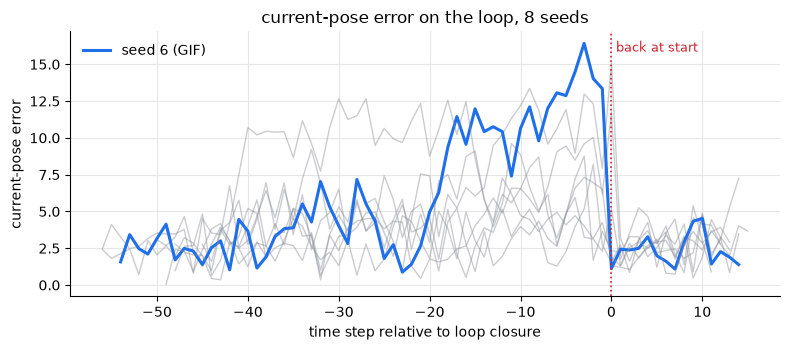

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for seed, (cur, k) in curves.items():
    x = np.arange(1, len(cur) + 1) - k   # align on the loop closure
    ax.plot(x, cur, "-", lw=2.2 if seed == 6 else 1, alpha=1 if seed == 6 else 0.45,
            color=viz.EST if seed == 6 else viz.TRUE, label="seed 6 (GIF)" if seed == 6 else None)
ax.axvline(0, color=viz.ERR, ls=":", lw=1.2)
ax.text(0.5, ax.get_ylim()[1] * 0.92, "back at start", color=viz.ERR, fontsize=9)
ax.set_xlabel("time step relative to loop closure")
ax.set_ylabel("current-pose error")
ax.set_title("current-pose error on the loop, 8 seeds")
ax.grid(True, color="#e6e6e6")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(ASSETS / "loop_closure.png", dpi=120)
plt.show()

The animation below (seed 6) shows the same run step by step: the true path in grey, the SLAM estimate in blue, and red lines from each estimated landmark to its true position. It's generated by `scripts/make_gif.py`.

![Graph SLAM on the loop, seed 6](../assets/slam_loop.gif)